In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from woody_filter import woody


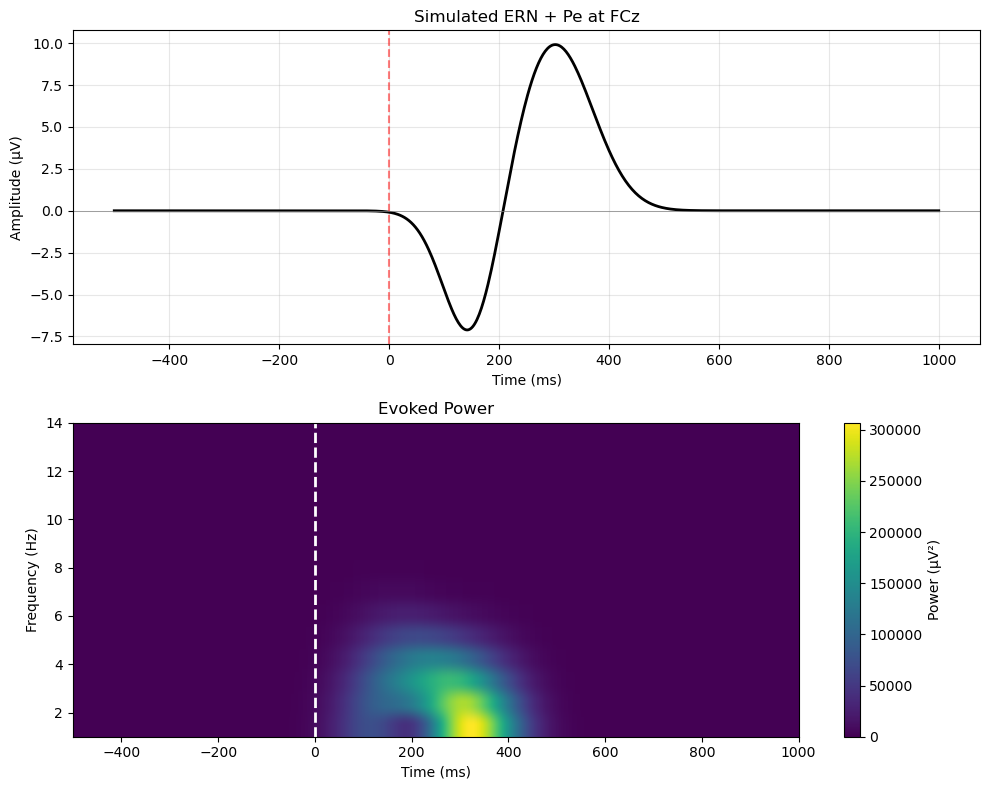

In [31]:
# ERP generation (Grand Average Waveform)
# Parameters
sfreq = 500  # Hz
tmin, tmax = -0.5, 1.0  # seconds
n_times = int((tmax - tmin) * sfreq) + 1
times = np.linspace(tmin, tmax, n_times)

# ERN parameters
ern_peak_time = 0.15  # 150ms post-error
ern_amplitude = -8  # microvolts 
ern_width = 0.05  # 50ms width

# Pe parameters
pe_peak_time = 0.3  # 300ms post-error
pe_amplitude = 10  # microvolts (positive deflection)
pe_width = 0.07  # 70ms width (broader than ERN)

# Generate ERN as Gaussian
ern = ern_amplitude * np.exp(-0.5 * ((times - ern_peak_time) / ern_width) ** 2)

# Generate Pe as Gaussian
pe = pe_amplitude * np.exp(-0.5 * ((times - pe_peak_time) / pe_width) ** 2)

# Combined ERP
erp = ern + pe

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# Morlet wavelets
tfr = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    # Shorter wavelet - max 0.5 seconds
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    
    convolved = np.convolve(erp, wavelet, mode='same')
    tfr[idx, :] = np.abs(convolved) ** 2

# Plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# ERP
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe at FCz')
ax1.grid(alpha=0.3)

# TFR
im = ax2.imshow(tfr, aspect='auto', origin='lower', 
                extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

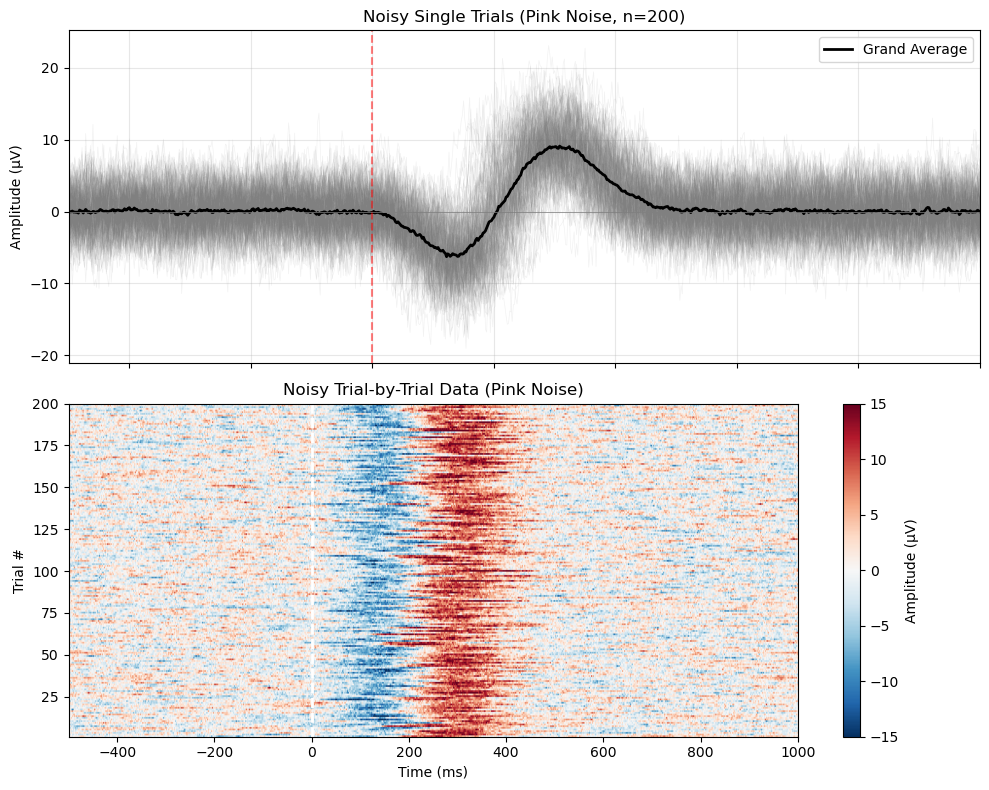

In [32]:
def generate_pink_noise(n_samples):
    """Generate pink (1/f) noise"""
    # Generate white noise
    white = np.random.randn(n_samples)
    # FFT
    fft_white = np.fft.rfft(white)
    # Create 1/f spectrum
    freqs = np.fft.rfftfreq(n_samples)
    freqs[0] = 1  # Avoid division by zero
    pink_fft = fft_white / np.sqrt(freqs)
    # Back to time domain
    pink = np.fft.irfft(pink_fft, n=n_samples)
    # Normalize
    pink = pink / np.std(pink)
    return pink

# Noise parameters
n_trials = 200
jitter_sd = 0.035  # 50ms temporal jitter
noise_amplitude = 3  # microvolts (pink noise SD)
amplitude_jitter_sd = 0.2  # 20% amplitude variability (coefficient of variation)

# Generate noisy trials
trials = np.zeros((n_trials, n_times))
true_jitters = np.zeros(n_trials)
true_ern_amplitudes = np.zeros(n_trials)
true_pe_amplitudes = np.zeros(n_trials)

for trial in range(n_trials):
    # Temporal jitter
    onset_jitter = np.random.normal(0, jitter_sd)
    onset_jitter = np.maximum(onset_jitter, -ern_peak_time)
    true_jitters[trial] = onset_jitter
    
    # Amplitude jitter (multiplicative, lognormal to keep sign consistent)
    ern_amp_factor = np.random.lognormal(0, amplitude_jitter_sd)
    pe_amp_factor = np.random.lognormal(0, amplitude_jitter_sd)
    true_ern_amplitudes[trial] = ern_amplitude * ern_amp_factor
    true_pe_amplitudes[trial] = pe_amplitude * pe_amp_factor
    
    # Generate ERN + Pe with jittered amplitudes
    ern = (ern_amplitude * ern_amp_factor) * np.exp(-0.5 * ((times - (ern_peak_time + onset_jitter)) / ern_width) ** 2)
    pe = (pe_amplitude * pe_amp_factor) * np.exp(-0.5 * ((times - (pe_peak_time + onset_jitter)) / pe_width) ** 2)
    
    # Add pink noise
    noise = generate_pink_noise(n_times) * noise_amplitude
    
    # Combine
    trials[trial, :] = ern + pe + noise

# Compute grand average
grand_avg = trials.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single trials with noise
ax1.plot(times * 1000, trials.T, 'gray', alpha=0.1, linewidth=0.5)
ax1.plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Noisy Single Trials (Pink Noise, n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all trials
im = ax2.imshow(trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-15, vmax=15)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Noisy Trial-by-Trial Data (Pink Noise)')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

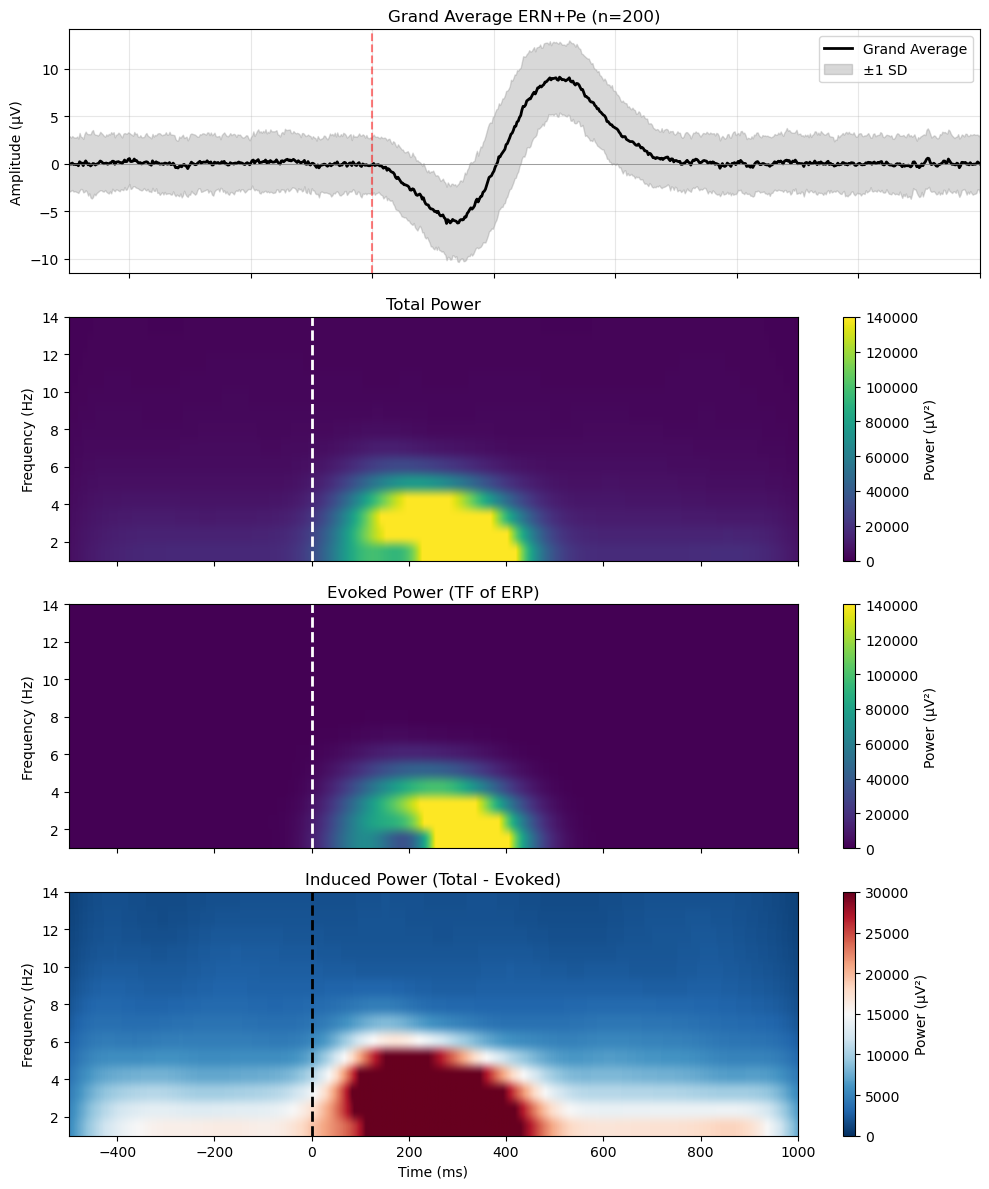

In [33]:
# Compute grand average and SD
grand_avg = trials.mean(axis=0)
sd = trials.std(axis=0)

# Time-Frequency Analysis
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER (TFR of averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER = Total - Evoked
tfr_induced = tfr_total - tfr_evoked

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power
im1 = axes[1].imshow(tfr_total, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (Total - Evoked)
im3 = axes[3].imshow(tfr_induced, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

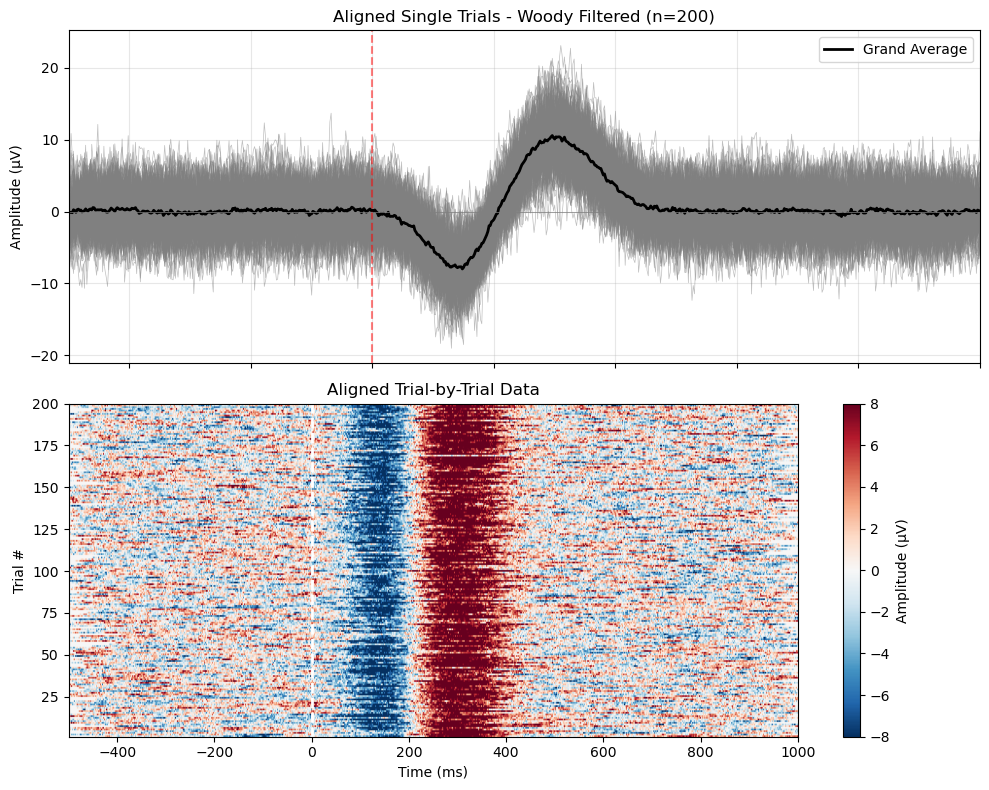

In [34]:
# Transpose to correct shape: (n_timepoints, n_trials)
trials_transposed = trials.T

# Apply iterative Woody filter
aligned_avg, detected_lags = woody(
    trials_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased'
)

# Reconstruct individual aligned trials
aligned_trials = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials[i, :] = trials[i, :]

grand_avg_aligned = aligned_trials.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single aligned trials
ax1.plot(times * 1000, aligned_trials.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Aligned Single Trials - Woody Filtered (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all aligned trials
im = ax2.imshow(aligned_trials, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Aligned Trial-by-Trial Data')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

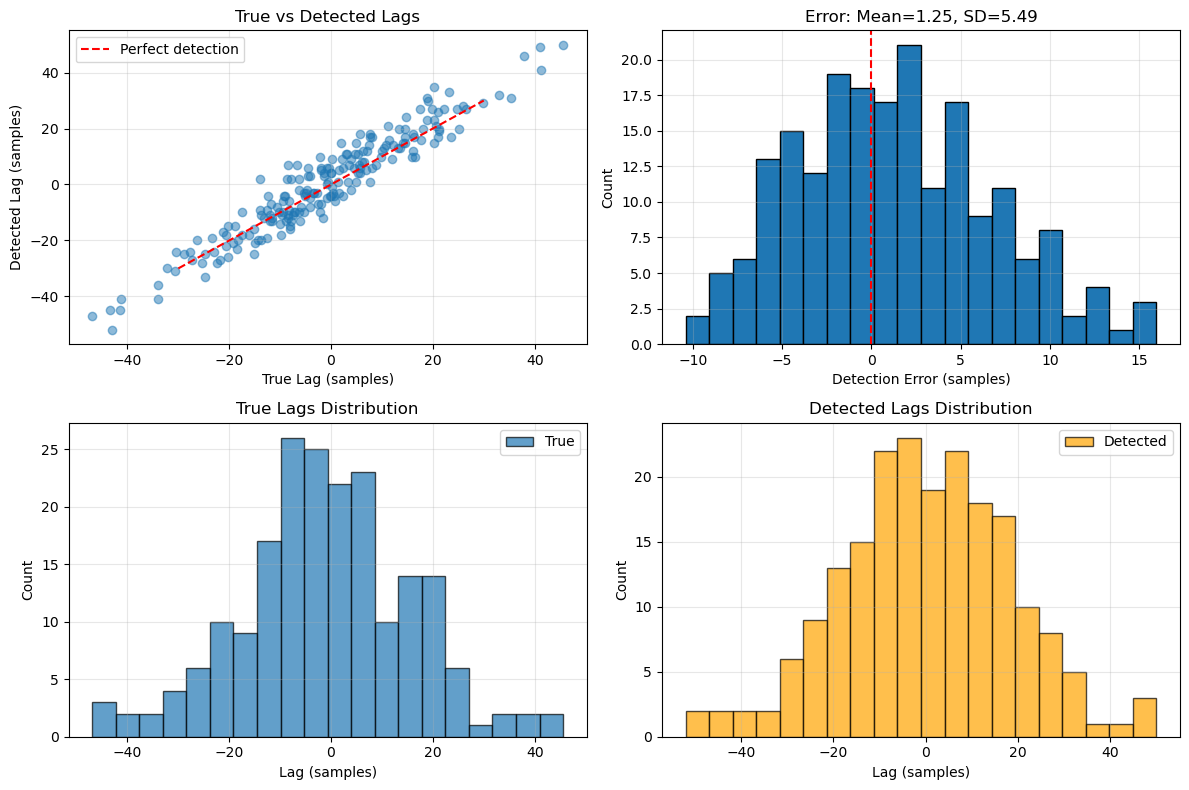

Correlation: 0.957


In [35]:
# Convert to same units
true_lags_samples = true_jitters * sfreq  # Convert seconds to samples

# Compare
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Scatter plot
axes[0, 0].scatter(true_lags_samples, detected_lags, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
error = detected_lags - true_lags_samples
axes[0, 1].hist(error, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error.mean():.2f}, SD={error.std():.2f}')
axes[0, 1].grid(alpha=0.3)

# True lags distribution
axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7, label='True')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Detected lags distribution
axes[1, 1].hist(detected_lags, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(true_lags_samples, detected_lags)[0,1]:.3f}")


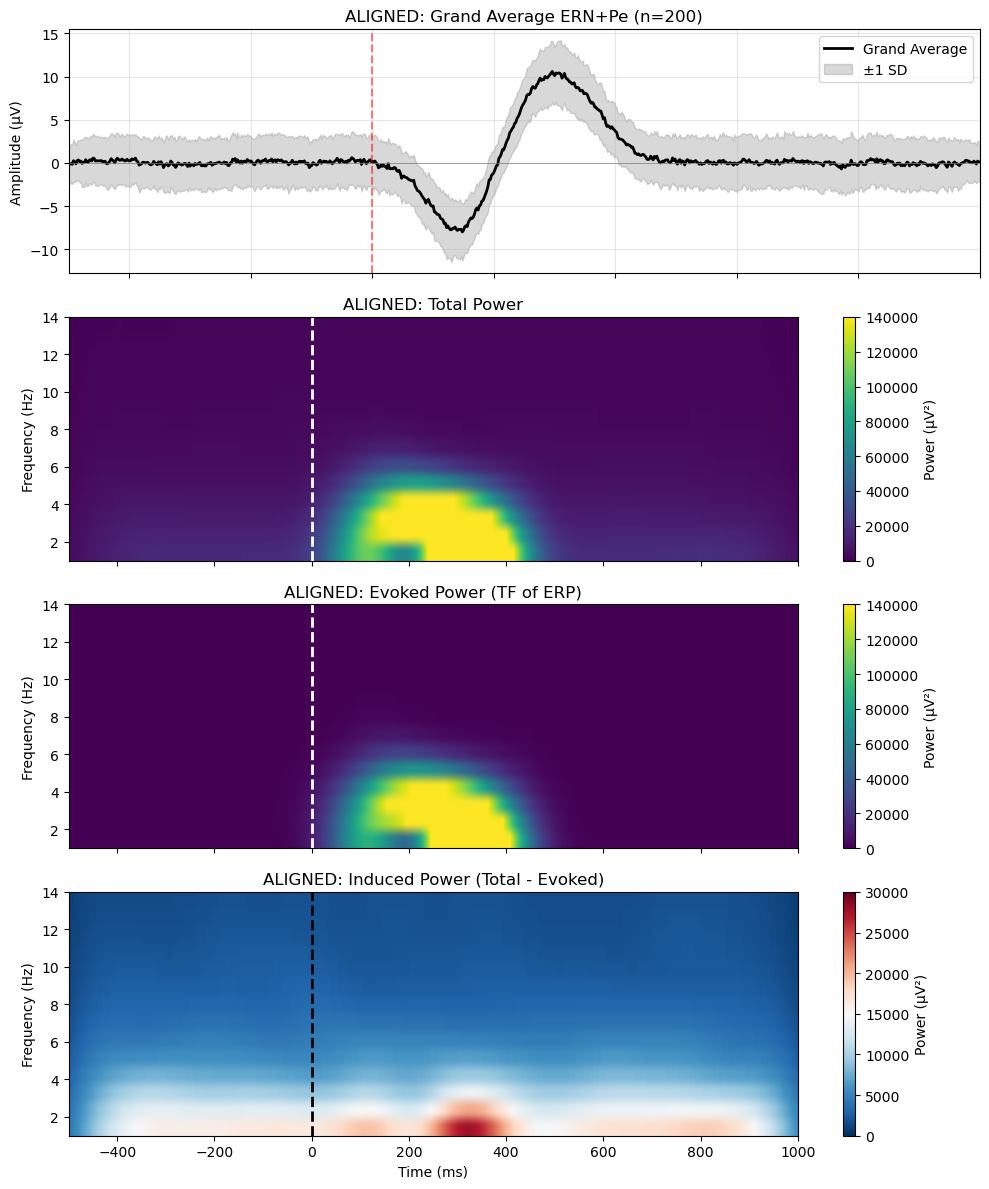

In [36]:
# Compute grand average and SD for ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# Time-Frequency Analysis on ALIGNED data
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER ALIGNED (TFR of averaged signal)
tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked_aligned[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER ALIGNED (average of single-trial TFRs)
tfr_total_aligned = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total_aligned[idx, :] += np.abs(convolved) ** 2
tfr_total_aligned /= n_trials

# INDUCED POWER ALIGNED = Total - Evoked
tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD (ALIGNED)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'ALIGNED: Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (ALIGNED)
im1 = axes[1].imshow(tfr_total_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('ALIGNED: Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power (ALIGNED)
im2 = axes[2].imshow(tfr_evoked_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('ALIGNED: Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (ALIGNED)
im3 = axes[3].imshow(tfr_induced_aligned, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('ALIGNED: Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

Run 0/1000: New best corr = 0.7291

Best correlation: 0.7293
Lag range: [-53, 49] samples
Lag std: 18.30 samples


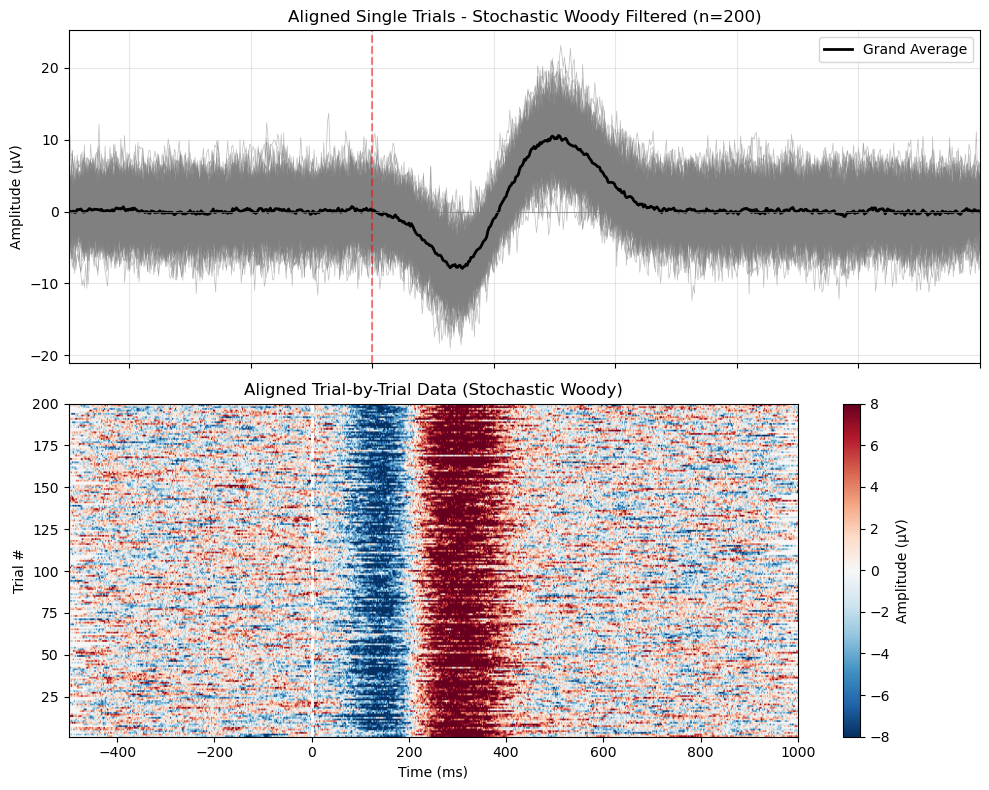

In [37]:
# Apply stochastic Woody filter
from woody_filter import woody_stochastic

aligned_avg_stoch, detected_lags_stoch, best_corr = woody_stochastic(
    trials_transposed,
    tol=0.1,
    max_it=100,
    xcorr_mthd='unbiased',
    max_lag_init=10,
    max_shift=50,
)

# Reconstruct individual aligned trials
aligned_trials_stoch = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_stoch[i]
    if lag > 0:
        aligned_trials_stoch[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_stoch[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_stoch[i, :] = trials[i, :]

grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Single aligned trials
ax1.plot(times * 1000, aligned_trials_stoch.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_stoch, 'k', linewidth=2, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Aligned Single Trials - Stochastic Woody Filtered (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

# Image of all aligned trials
im = ax2.imshow(aligned_trials_stoch, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title('Aligned Trial-by-Trial Data (Stochastic Woody)')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

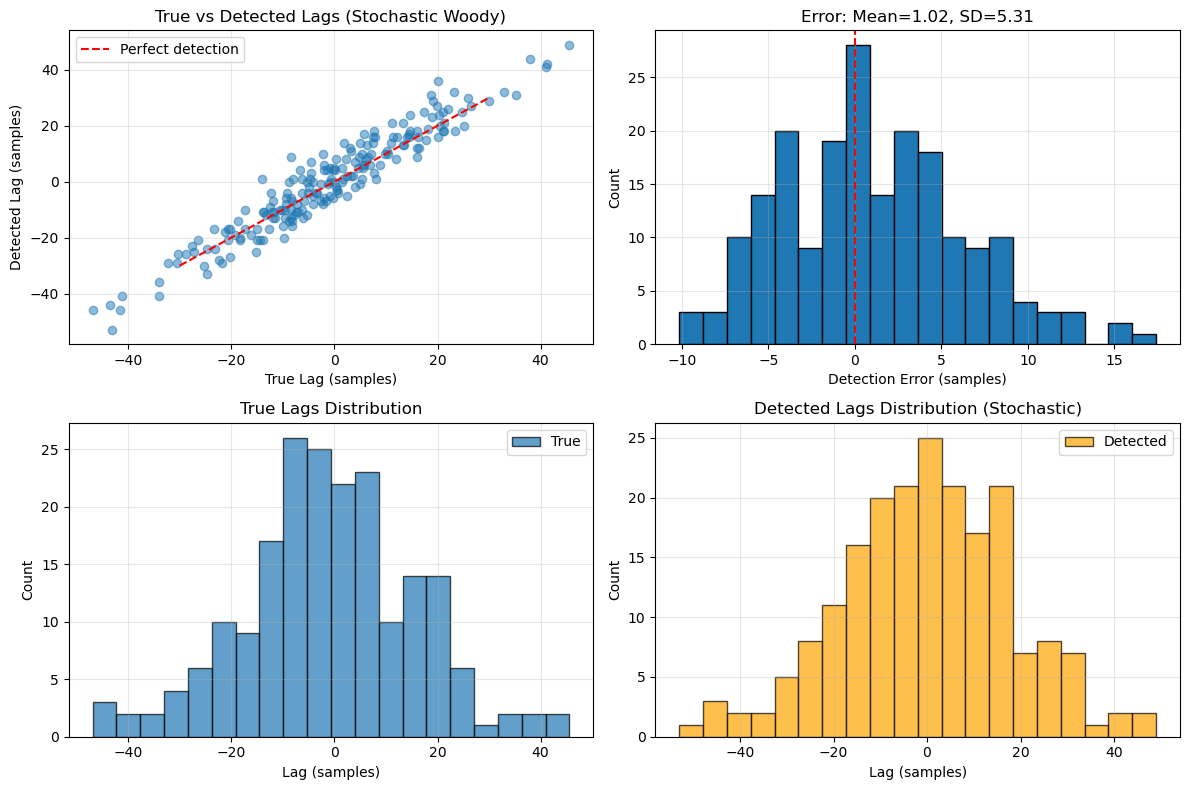

Correlation: 0.958


In [38]:
# Convert to same units
true_lags_samples = true_jitters * sfreq  # Convert seconds to samples

# Compare
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Scatter plot
axes[0, 0].scatter(true_lags_samples, detected_lags_stoch, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags (Stochastic Woody)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
error_stoch = detected_lags_stoch - true_lags_samples
axes[0, 1].hist(error_stoch, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error_stoch.mean():.2f}, SD={error_stoch.std():.2f}')
axes[0, 1].grid(alpha=0.3)

# True lags distribution
axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7, label='True')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Detected lags distribution
axes[1, 1].hist(detected_lags_stoch, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution (Stochastic)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(true_lags_samples, detected_lags_stoch)[0,1]:.3f}")

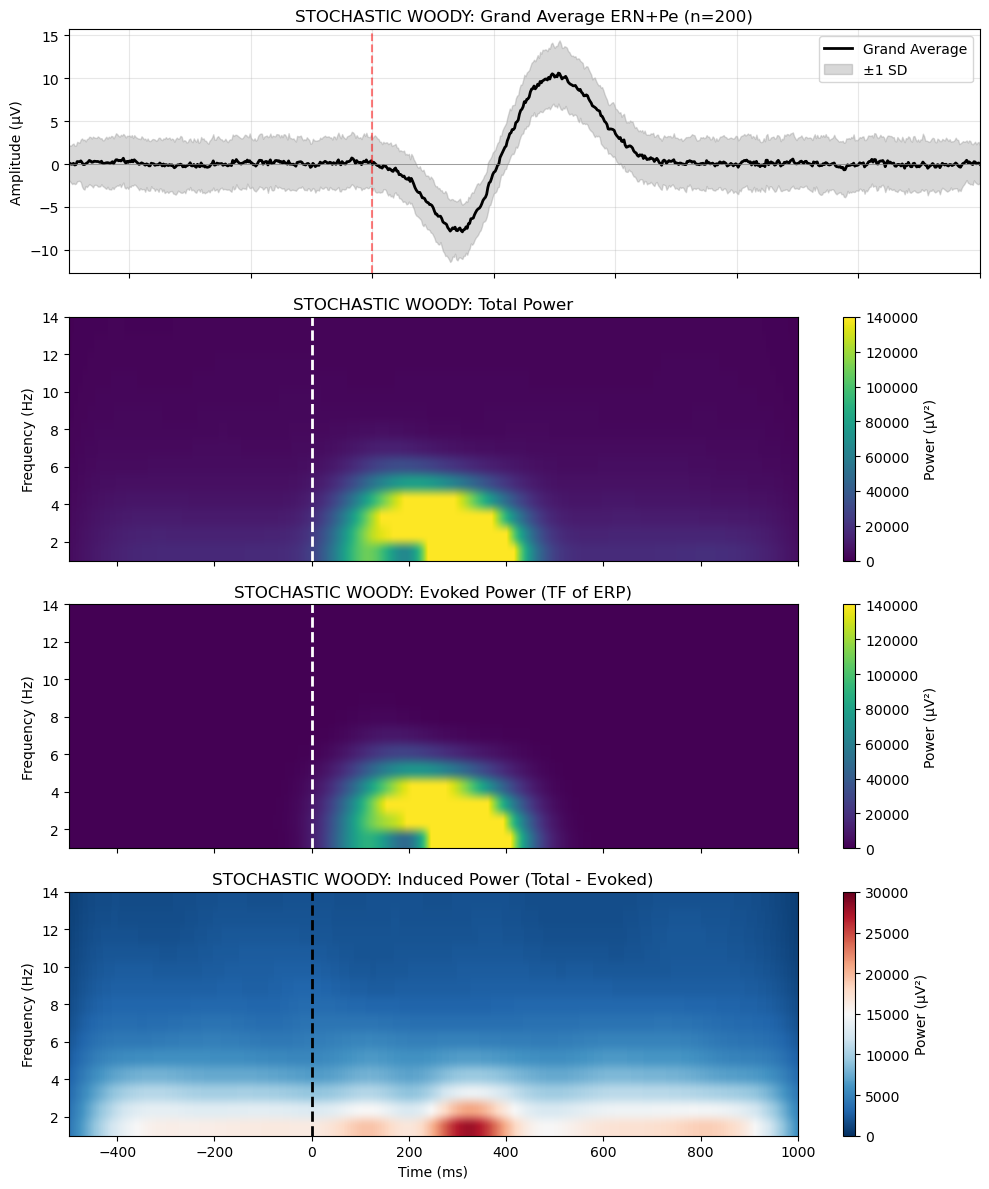

In [39]:
# Compute grand average and SD for STOCHASTIC ALIGNED trials
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)
sd_stoch = aligned_trials_stoch.std(axis=0)

# Time-Frequency Analysis on STOCHASTIC ALIGNED data
freqs = np.arange(1, 15, 1)  # 1-15 Hz
n_cycles = freqs / 2.0

# EVOKED POWER STOCHASTIC (TFR of averaged signal)
tfr_evoked_stoch = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_stoch, wavelet, mode='same')
    tfr_evoked_stoch[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER STOCHASTIC (average of single-trial TFRs)
tfr_total_stoch = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials_stoch[trial, :], wavelet, mode='same')
        tfr_total_stoch[idx, :] += np.abs(convolved) ** 2
tfr_total_stoch /= n_trials

# INDUCED POWER STOCHASTIC = Total - Evoked
tfr_induced_stoch = tfr_total_stoch - tfr_evoked_stoch

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Grand average ERP with SD (STOCHASTIC)
axes[0].plot(times * 1000, grand_avg_stoch, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg_stoch - sd_stoch, grand_avg_stoch + sd_stoch, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'STOCHASTIC WOODY: Grand Average ERN+Pe (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (STOCHASTIC)
im1 = axes[1].imshow(tfr_total_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('STOCHASTIC WOODY: Total Power')
plt.colorbar(im1, ax=axes[1], label='Power (µV²)')

# Evoked Power (STOCHASTIC)
im2 = axes[2].imshow(tfr_evoked_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('STOCHASTIC WOODY: Evoked Power (TF of ERP)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (STOCHASTIC)
im3 = axes[3].imshow(tfr_induced_stoch, aspect='auto', origin='lower', 
                     extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                     cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('STOCHASTIC WOODY: Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3], label='Power (µV²)')

plt.tight_layout()
plt.show()

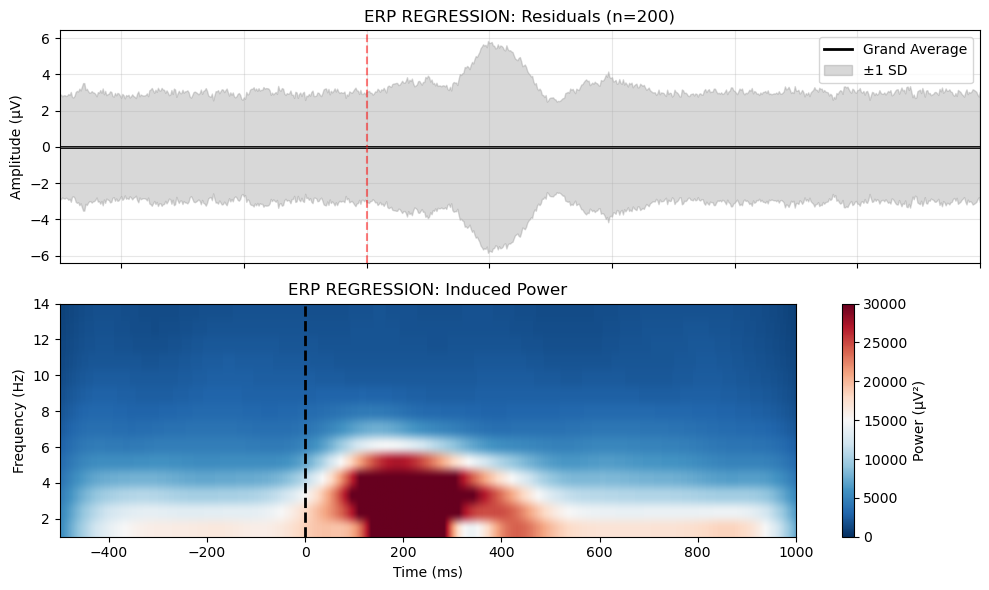

In [40]:
from scipy.stats import linregress

# Regress ERP from single trials, residuals are the induced activity
trials_regressed = np.zeros_like(trials)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg, trials[t_idx, :])
    trials_regressed[t_idx, :] = trials[t_idx, :] - (intercept + slope * grand_avg)

grand_avg_reg = trials_regressed.mean(axis=0)
sd_reg = trials_regressed.std(axis=0)

# TFR on regressed trials - Induced Power
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_induced_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_regressed[trial, :], wavelet, mode='same')
        tfr_induced_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_reg /= n_trials

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(times * 1000, grand_avg_reg, 'k', linewidth=2, label='Grand Average')
ax1.fill_between(times * 1000, grand_avg_reg - sd_reg, grand_avg_reg + sd_reg, 
                 color='gray', alpha=0.3, label='±1 SD')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'ERP REGRESSION: Residuals (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

im = ax2.imshow(tfr_induced_reg, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('ERP REGRESSION: Induced Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

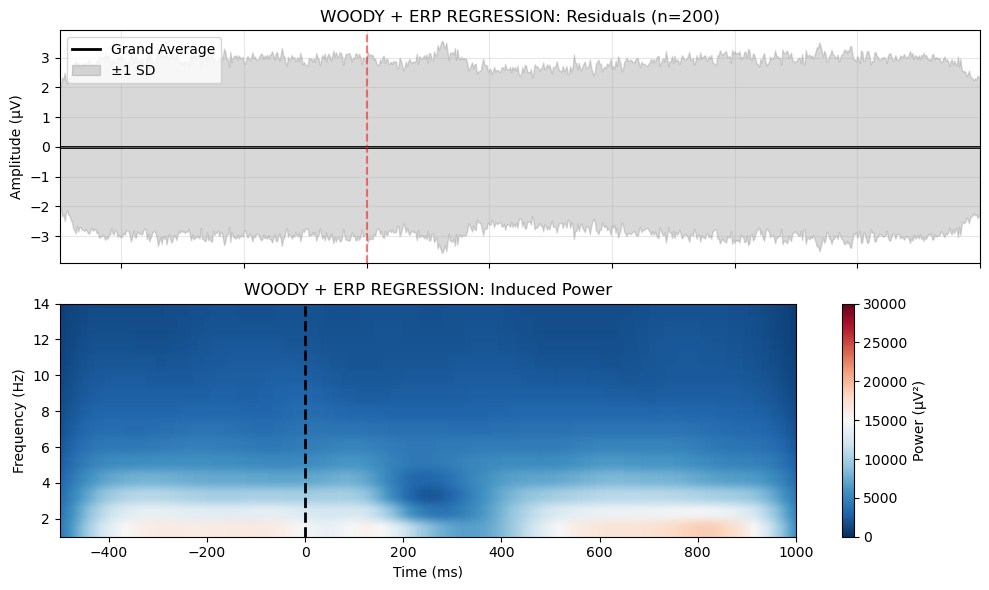

In [41]:
# Woody-aligned trials + ERP regression

grand_avg_aligned = aligned_trials.mean(axis=0)

trials_aligned_regressed = np.zeros_like(aligned_trials)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_aligned, aligned_trials[t_idx, :])
    trials_aligned_regressed[t_idx, :] = aligned_trials[t_idx, :] - (intercept + slope * grand_avg_aligned)

grand_avg_aligned_reg = trials_aligned_regressed.mean(axis=0)
sd_aligned_reg = trials_aligned_regressed.std(axis=0)

# TFR on regressed trials = Induced Power directly
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_induced_aligned_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_aligned_regressed[trial, :], wavelet, mode='same')
        tfr_induced_aligned_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_aligned_reg /= n_trials

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(times * 1000, grand_avg_aligned_reg, 'k', linewidth=2, label='Grand Average')
ax1.fill_between(times * 1000, grand_avg_aligned_reg - sd_aligned_reg, grand_avg_aligned_reg + sd_aligned_reg, 
                 color='gray', alpha=0.3, label='±1 SD')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'WOODY + ERP REGRESSION: Residuals (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

im = ax2.imshow(tfr_induced_aligned_reg, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('WOODY + ERP REGRESSION: Induced Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

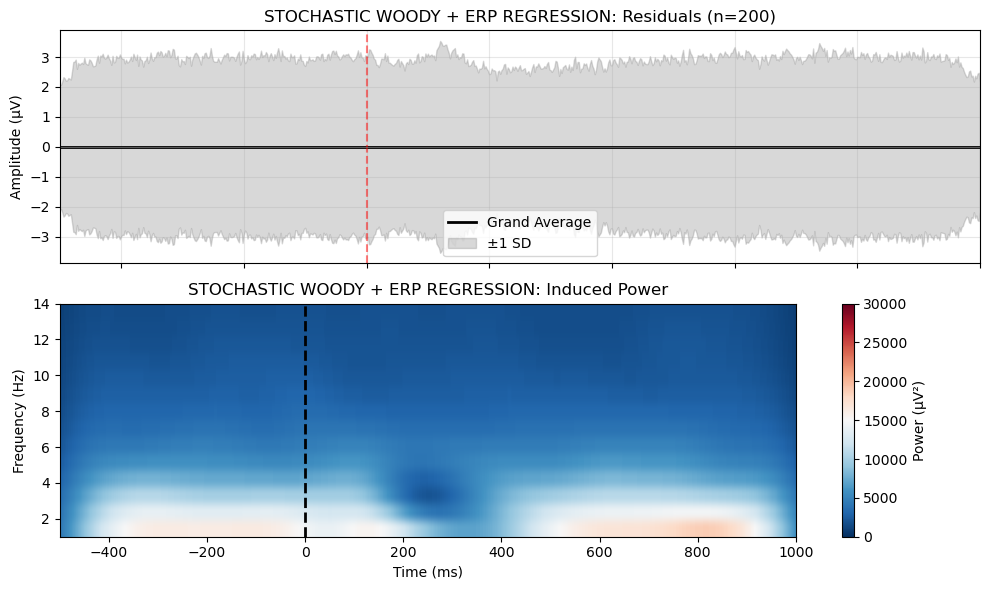

In [42]:
# Stochastic Woody-aligned trials
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

trials_stoch_regressed = np.zeros_like(aligned_trials_stoch)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_stoch, aligned_trials_stoch[t_idx, :])
    trials_stoch_regressed[t_idx, :] = aligned_trials_stoch[t_idx, :] - (intercept + slope * grand_avg_stoch)

grand_avg_stoch_reg = trials_stoch_regressed.mean(axis=0)
sd_stoch_reg = trials_stoch_regressed.std(axis=0)

# TFR on regressed trials = Induced Power
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_induced_stoch_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_stoch_regressed[trial, :], wavelet, mode='same')
        tfr_induced_stoch_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_stoch_reg /= n_trials

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(times * 1000, grand_avg_stoch_reg, 'k', linewidth=2, label='Grand Average')
ax1.fill_between(times * 1000, grand_avg_stoch_reg - sd_stoch_reg, grand_avg_stoch_reg + sd_stoch_reg, 
                 color='gray', alpha=0.3, label='±1 SD')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'STOCHASTIC WOODY + ERP REGRESSION: Residuals (n={n_trials})')
ax1.legend()
ax1.grid(alpha=0.3)

im = ax2.imshow(tfr_induced_stoch_reg, aspect='auto', origin='lower', 
                extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('STOCHASTIC WOODY + ERP REGRESSION: Induced Power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')

plt.tight_layout()
plt.show()

In [44]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import linregress
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
from woody_filter import woody_stochastic

warnings.filterwarnings('ignore')

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw, Stochastic Woody, and Woody + Regression TFR."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract incorrect trials
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 5:
        return None
    
    # Get data
    data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)
    
    # === RAW ANALYSIS ===
    grand_avg_raw = data_uv.mean(axis=0)
    sd_raw = data_uv.std(axis=0)
    
    # Raw - Total Power
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(convolved) ** 2
    tfr_total_raw /= n_trials
    
    # Raw - Induced Power
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_raw[idx, :] += np.abs(convolved) ** 2
    tfr_induced_raw /= n_trials
    
    # Baseline correction
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === STOCHASTIC WOODY ANALYSIS ===
    data_T = data_uv.T
    
    aligned_avg, detected_lags, corr_coef = woody_stochastic(
        data_T,
        tol=0.1,
        max_it=100,
        n_runs=1000,
        max_lag_init=10,
        xcorr_mthd='unbiased',
        max_shift=50
    )
    
    # Reconstruct aligned trials
    n_trials_data, n_times = data_uv.shape
    aligned_trials = np.zeros_like(data_uv)
    
    for i in range(n_trials_data):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    grand_avg_woody = aligned_trials.mean(axis=0)
    sd_woody = aligned_trials.std(axis=0)
    
    # Woody - Total Power
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(convolved) ** 2
    tfr_total_woody /= n_trials
    
    # Woody - Induced Power (simple subtraction)
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody /= n_trials
    
    # Baseline correction
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === WOODY + ERP REGRESSION ===
    # Regress ERP from aligned single trials
    trials_woody_reg = np.zeros_like(aligned_trials)
    for t_idx in range(n_trials):
        slope, intercept, _, _, _ = linregress(grand_avg_woody, aligned_trials[t_idx, :])
        trials_woody_reg[t_idx, :] = aligned_trials[t_idx, :] - (intercept + slope * grand_avg_woody)
    
    grand_avg_woody_reg = trials_woody_reg.mean(axis=0)
    sd_woody_reg = trials_woody_reg.std(axis=0)
    
    # TFR on regressed trials = Induced Power directly
    tfr_induced_woody_reg = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(trials_woody_reg[trial, :], wavelet, mode='same')
            tfr_induced_woody_reg[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody_reg /= n_trials
    
    # Baseline correction
    bl_induced_woody_reg = tfr_induced_woody_reg[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_induced_woody_reg_pct = ((tfr_induced_woody_reg - bl_induced_woody_reg) / bl_induced_woody_reg) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    results = {
        'n_trials': n_trials,
        'mean_lag': detected_lags.mean(),
        'std_lag': detected_lags.std(),
        # Raw
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        # Woody
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        # Woody + Regression
        'theta_induced_woody_reg': tfr_induced_woody_reg_pct[theta_mask, :][:, time_mask].mean(),
        # ERPs
        'erp_raw': grand_avg_raw,
        'sd_raw': sd_raw,
        'erp_woody': grand_avg_woody,
        'sd_woody': sd_woody,
        'erp_woody_reg': grand_avg_woody_reg,
        'sd_woody_reg': sd_woody_reg,
        # TFRs
        'tfr_total_raw_pct': tfr_total_raw_pct,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_total_woody_pct': tfr_total_woody_pct,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'tfr_induced_woody_reg_pct': tfr_induced_woody_reg_pct,
        'times': times,
        'freqs': freqs
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

# Analyze all subjects
all_results = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject(sub_file, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f"\n{len(all_results)} subjects analyzed successfully")

Processing subjects:   0%|          | 0/156 [00:00<?, ?it/s]

Run 0/1000: New best corr = 0.4234


Processing subjects:   1%|          | 1/156 [00:02<05:57,  2.30s/it]


Best correlation: 0.4533
Lag range: [-9, 51] samples
Lag std: 17.41 samples
Run 0/1000: New best corr = 0.5464

Best correlation: 0.5527
Lag range: [-53, 60] samples
Lag std: 24.74 samples


Processing subjects:   1%|▏         | 2/156 [00:16<23:18,  9.08s/it]

Run 0/1000: New best corr = 0.4399


... (302 outputs left out)

Processing subjects:  99%|█████████▉| 155/156 [18:40<00:08,  8.54s/it]

Run 0/1000: New best corr = 0.2721

Best correlation: 0.2857
Lag range: [-49, 59] samples
Lag std: 25.04 samples


Processing subjects: 100%|██████████| 156/156 [18:54<00:00,  7.27s/it]


155 subjects analyzed successfully


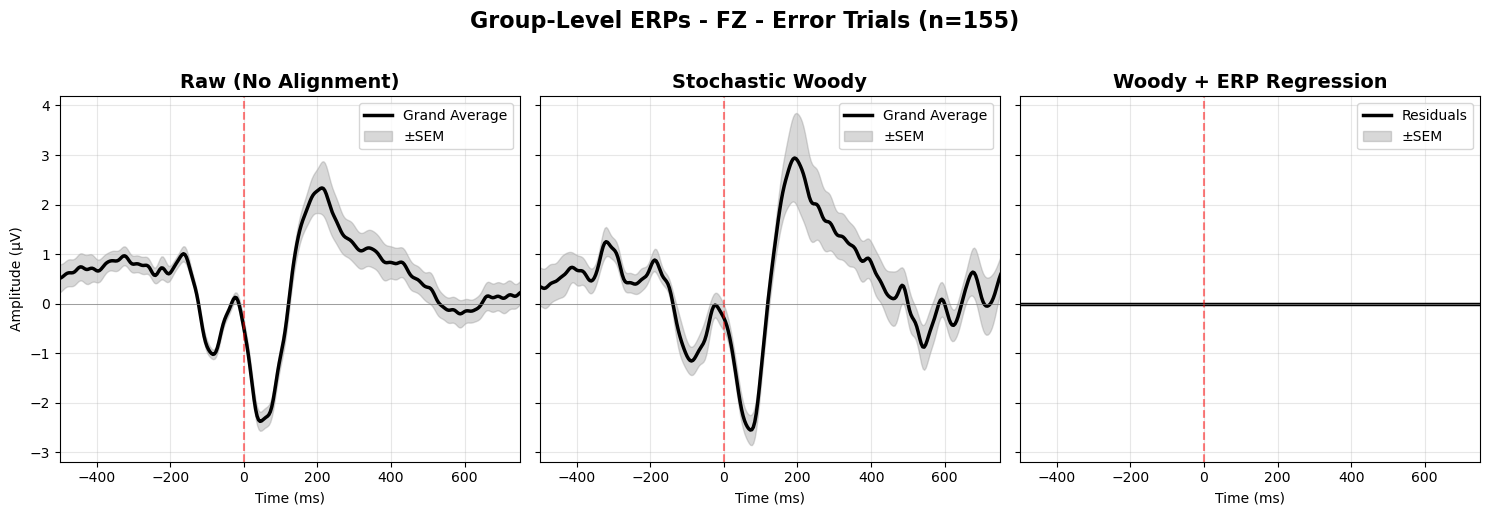

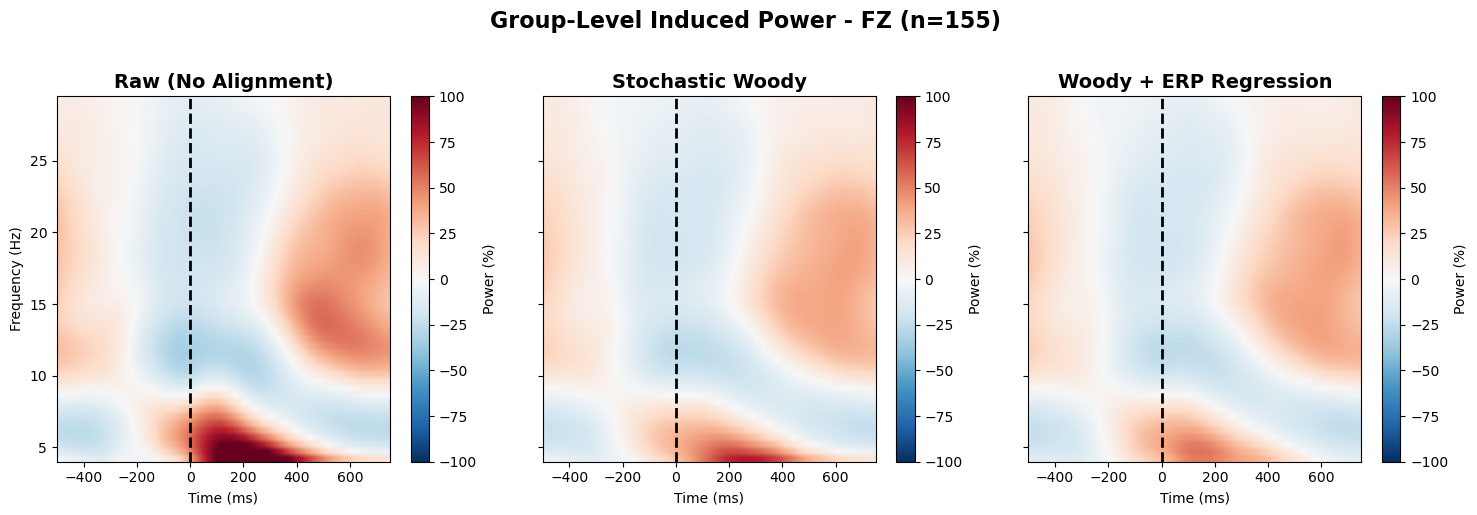

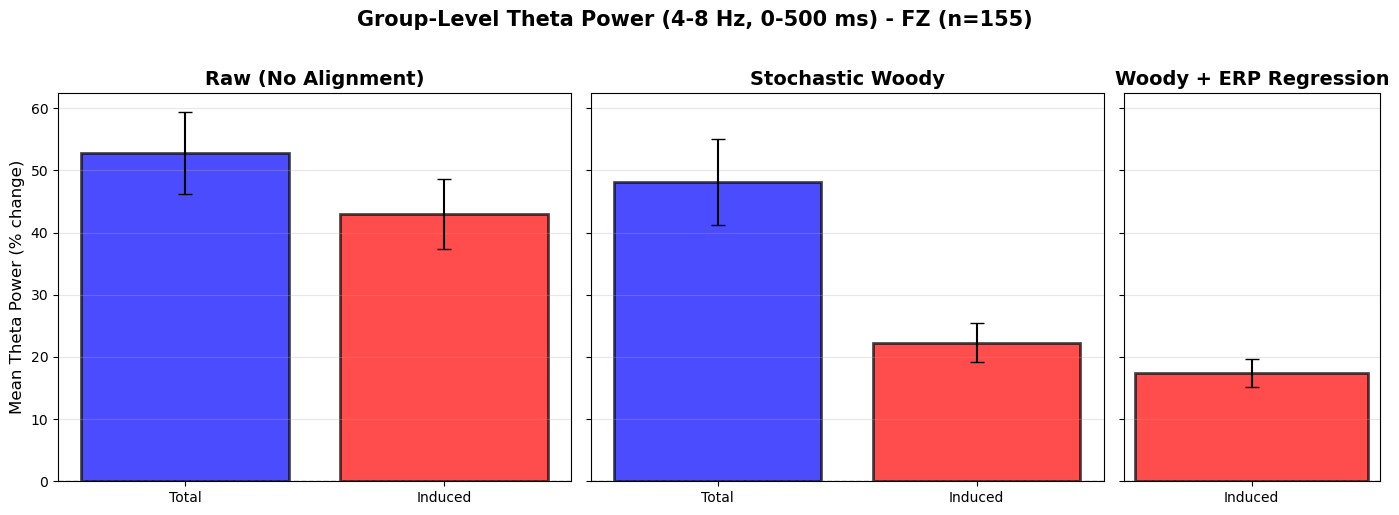


=== SUMMARY STATISTICS ===
Raw       - Total: 52.82±6.60%, Induced: 42.98±5.58%
Woody     - Total: 48.11±6.86%, Induced: 22.30±3.09%
Woody+Reg - Induced: 17.40±2.24%

Results saved to 'theta_analysis_results_all_methods.csv'


In [46]:
# === COMPUTE GROUP AVERAGES ===
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_woody_reg_all = np.array([r['erp_woody_reg'] for r in all_results])

erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_reg_mean = erp_woody_reg_all.mean(axis=0)
erp_woody_reg_sem = erp_woody_reg_all.std(axis=0) / np.sqrt(len(all_results))

tfr_induced_raw_all = np.array([r['tfr_induced_raw_pct'] for r in all_results])
tfr_induced_woody_all = np.array([r['tfr_induced_woody_pct'] for r in all_results])
tfr_induced_woody_reg_all = np.array([r['tfr_induced_woody_reg_pct'] for r in all_results])

tfr_induced_raw_mean = tfr_induced_raw_all.mean(axis=0)
tfr_induced_woody_mean = tfr_induced_woody_all.mean(axis=0)
tfr_induced_woody_reg_mean = tfr_induced_woody_reg_all.mean(axis=0)

# === PLOT 1: ERPs ===
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

axes[0].plot(times * 1000, erp_raw_mean, 'k', linewidth=2.5, label='Grand Average')
axes[0].fill_between(times * 1000, erp_raw_mean - erp_raw_sem, erp_raw_mean + erp_raw_sem,
                     color='gray', alpha=0.3, label='±SEM')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title('Raw (No Alignment)', fontsize=14, fontweight='bold')
axes[0].set_xlim(-500, 750)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(times * 1000, erp_woody_mean, 'k', linewidth=2.5, label='Grand Average')
axes[1].fill_between(times * 1000, erp_woody_mean - erp_woody_sem, erp_woody_mean + erp_woody_sem,
                     color='gray', alpha=0.3, label='±SEM')
axes[1].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[1].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[1].set_xlabel('Time (ms)')
axes[1].set_title('Stochastic Woody', fontsize=14, fontweight='bold')
axes[1].set_xlim(-500, 750)
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(times * 1000, erp_woody_reg_mean, 'k', linewidth=2.5, label='Residuals')
axes[2].fill_between(times * 1000, erp_woody_reg_mean - erp_woody_reg_sem, erp_woody_reg_mean + erp_woody_reg_sem,
                     color='gray', alpha=0.3, label='±SEM')
axes[2].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[2].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[2].set_xlabel('Time (ms)')
axes[2].set_title('Woody + ERP Regression', fontsize=14, fontweight='bold')
axes[2].set_xlim(-500, 750)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle(f'Group-Level ERPs - FZ - Error Trials (n={len(all_results)})', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: INDUCED TFRs ===
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

im0 = axes[0].imshow(tfr_induced_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Raw (No Alignment)', fontsize=14, fontweight='bold')
axes[0].set_xlim(-500, 750)
plt.colorbar(im0, ax=axes[0], label='Power (%)')

im1 = axes[1].imshow(tfr_induced_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Time (ms)')
axes[1].set_title('Stochastic Woody', fontsize=14, fontweight='bold')
axes[1].set_xlim(-500, 750)
plt.colorbar(im1, ax=axes[1], label='Power (%)')

im2 = axes[2].imshow(tfr_induced_woody_reg_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_title('Woody + ERP Regression', fontsize=14, fontweight='bold')
axes[2].set_xlim(-500, 750)
plt.colorbar(im2, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level Induced Power - FZ (n={len(all_results)})', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 3: THETA BARPLOTS ===
df = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in all_results])

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True,
                         gridspec_kw={'width_ratios': [2, 2, 1]})

x_pos = np.arange(2)

# Raw
raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Mean Theta Power (% change)', fontsize=12)
axes[0].set_title('Raw (No Alignment)', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

# Woody
woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title('Stochastic Woody', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

# Woody + Regression (only induced)
woody_reg_mean = df['theta_induced_woody_reg'].mean()
woody_reg_sem = df['theta_induced_woody_reg'].sem()
axes[2].bar([0], [woody_reg_mean], yerr=[woody_reg_sem], color='red',
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[2].set_xticks([0])
axes[2].set_xticklabels(['Induced'])
axes[2].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[2].set_title('Woody + ERP Regression', fontsize=14, fontweight='bold')
axes[2].grid(alpha=0.3, axis='y')

plt.suptitle(f'Group-Level Theta Power (4-8 Hz, 0-500 ms) - FZ (n={len(df)})',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== SUMMARY STATISTICS ===")
print(f"Raw       - Total: {raw_means[0]:.2f}±{raw_sems[0]:.2f}%, Induced: {raw_means[1]:.2f}±{raw_sems[1]:.2f}%")
print(f"Woody     - Total: {woody_means[0]:.2f}±{woody_sems[0]:.2f}%, Induced: {woody_means[1]:.2f}±{woody_sems[1]:.2f}%")
print(f"Woody+Reg - Induced: {woody_reg_mean:.2f}±{woody_reg_sem:.2f}%")

df.to_csv('theta_analysis_results_all_methods.csv', index=False)
print("\nResults saved to 'theta_analysis_results_all_methods.csv'")

In [47]:
import sys
sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')

from lagged_autocoherence import lagged_hilbert_autocoherence
from pathlib import Path
from tqdm import tqdm
import pandas as pd
import mne
import numpy as np
from scipy.stats import linregress
from woody_filter import woody_stochastic

def analyze_subject_induced_autocoherence(epochs_path, freqs_range, lags_range, time_window=(-1, 1.5)):
    """
    Compute autocoherence for raw induced, Woody induced, and Woody + regression induced.
    """
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract error trials
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 10:
        return None
    
    # Get data
    data = epochs_incorrect.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    # Crop to time window
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    # === RAW INDUCED (subtract grand average) ===
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    # === WOODY ALIGNMENT ===
    data_T = data_uv.T
    aligned_avg, detected_lags, corr_coef = woody_stochastic(
        data_T,
        tol=0.1,
        max_it=100,
        n_runs=1000,
        max_lag_init=10,
        xcorr_mthd='unbiased',
        max_shift=50
    )
    
    # Reconstruct aligned trials
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    # Crop aligned trials
    data_woody_cropped = aligned_trials[:, time_mask]
    
    # === WOODY INDUCED (subtract aligned grand average) ===
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    # === WOODY + ERP REGRESSION ===
    data_induced_woody_reg = np.zeros_like(data_woody_cropped)
    for t_idx in range(n_trials):
        slope, intercept, _, _, _ = linregress(grand_avg_woody, data_woody_cropped[t_idx, :])
        data_induced_woody_reg[t_idx, :] = data_woody_cropped[t_idx, :] - (intercept + slope * grand_avg_woody)
    
    # === COMPUTE AUTOCOHERENCE ===
    lcs_induced_raw = lagged_hilbert_autocoherence(
        data_induced_raw,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
    )
    
    lcs_induced_woody = lagged_hilbert_autocoherence(
        data_induced_woody,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
    )
    
    lcs_induced_woody_reg = lagged_hilbert_autocoherence(
        data_induced_woody_reg,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
    )
    
    results = {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lcs_induced_raw': lcs_induced_raw,
        'lcs_induced_woody': lcs_induced_woody,
        'lcs_induced_woody_reg': lcs_induced_woody_reg,
        'mean_lag_ms': detected_lags.mean() / sfreq * 1000,
        'std_lag_ms': detected_lags.std() / sfreq * 1000
    }
    
    return results


# === SETUP ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

freqs_range = np.arange(4, 30, 1)
lags_range = np.arange(0.5, 5, 0.25)

# Run analysis
all_results_induced = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject_induced_autocoherence(sub_file, freqs_range, lags_range)
        if results is not None:
            all_results_induced.append(results)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue

print(f"\n{len(all_results_induced)} subjects analyzed successfully")

Processing subjects:   0%|          | 0/156 [00:00<?, ?it/s]

Run 0/1000: New best corr = 0.4351

Best correlation: 0.4540
Lag range: [-8, 48] samples
Lag std: 16.24 samples


Processing subjects:   1%|          | 1/156 [00:04<12:05,  4.68s/it]

Run 0/1000: New best corr = 0.5511

Best correlation: 0.5533
Lag range: [-54, 60] samples
Lag std: 26.47 samples


Processing subjects:   1%|▏         | 2/156 [00:24<34:46, 13.55s/it]

Run 0/1000: New best corr = 0.4362

Best correlation: 0.4642
Lag range: [-16, 15] samples
Lag std: 8.34 samples


... (302 outputs left out)

Processing subjects:  99%|█████████▉| 155/156 [28:43<00:12, 12.80s/it]

Run 0/1000: New best corr = 0.2682

Best correlation: 0.2821
Lag range: [-50, 57] samples
Lag std: 26.79 samples


Processing subjects: 100%|██████████| 156/156 [29:03<00:00, 11.18s/it]


155 subjects analyzed successfully


Group statistics (INDUCED):
  Raw induced      - mean: 0.096, max: 0.853
  Woody induced    - mean: 0.096, max: 0.858
  Woody+Reg induced - mean: 0.096, max: 0.861


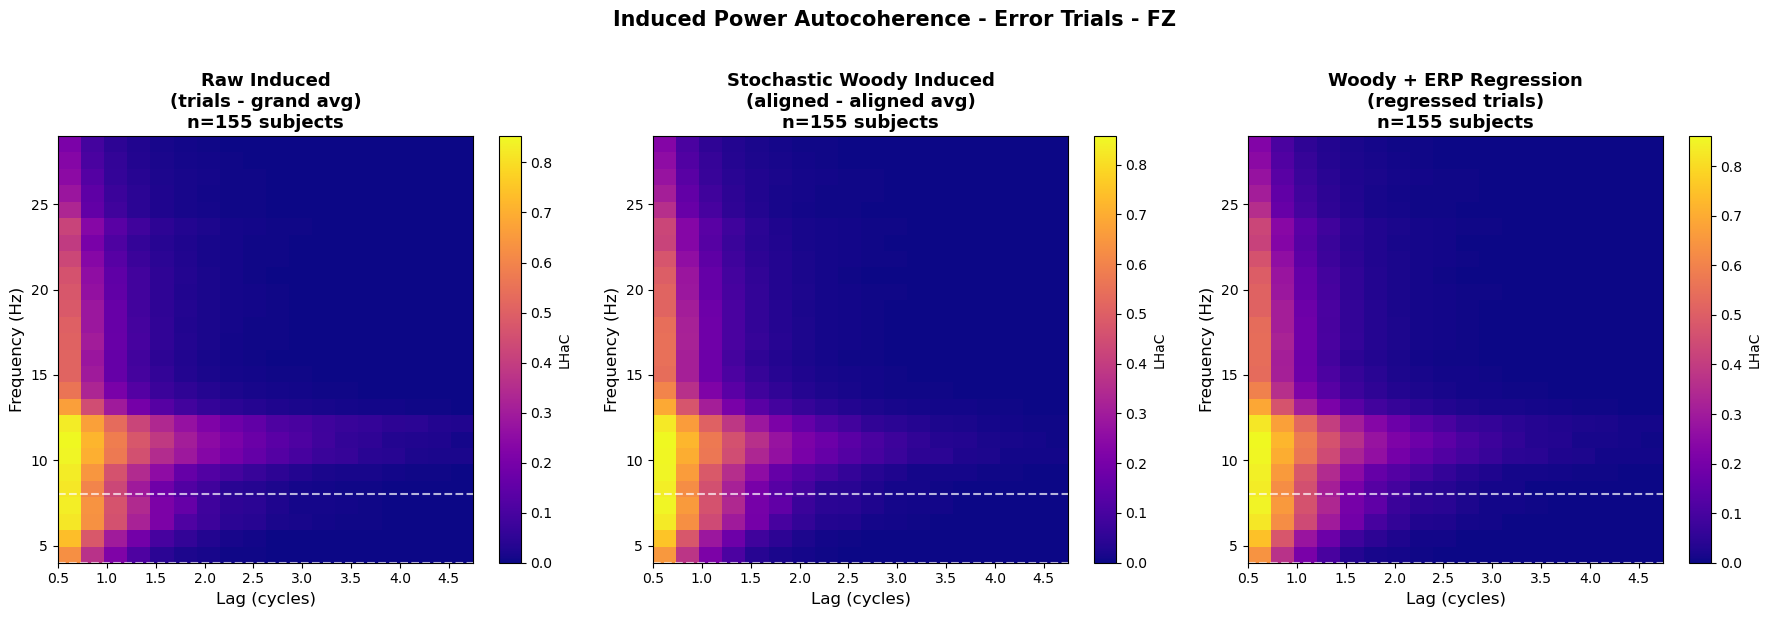


THETA BAND STATISTICS (4-8 Hz):

Raw induced:        0.130
Woody induced:      0.129 (+0.2%)
Woody+Reg induced:  0.128 (+0.9%)

BETA BAND STATISTICS (13-30 Hz):

Raw induced:        0.056
Woody induced:      0.061 (-8.4%)
Woody+Reg induced:  0.061 (-7.8%)


In [48]:
# Extract autocoherence data for all three conditions
lcs_induced_raw_all = []
lcs_induced_woody_all = []
lcs_induced_woody_reg_all = []

for result in all_results_induced:
    lcs_induced_raw_all.append(result['lcs_induced_raw'].mean(axis=0))
    lcs_induced_woody_all.append(result['lcs_induced_woody'].mean(axis=0))
    lcs_induced_woody_reg_all.append(result['lcs_induced_woody_reg'].mean(axis=0))

# Convert to arrays and average across subjects
lcs_induced_raw_all = np.array(lcs_induced_raw_all)
lcs_induced_woody_all = np.array(lcs_induced_woody_all)
lcs_induced_woody_reg_all = np.array(lcs_induced_woody_reg_all)

lhc_induced_raw_mean = lcs_induced_raw_all.mean(axis=0)
lhc_induced_woody_mean = lcs_induced_woody_all.mean(axis=0)
lhc_induced_woody_reg_mean = lcs_induced_woody_reg_all.mean(axis=0)

print(f"Group statistics (INDUCED):")
print(f"  Raw induced      - mean: {lhc_induced_raw_mean.mean():.3f}, max: {lhc_induced_raw_mean.max():.3f}")
print(f"  Woody induced    - mean: {lhc_induced_woody_mean.mean():.3f}, max: {lhc_induced_woody_mean.max():.3f}")
print(f"  Woody+Reg induced - mean: {lhc_induced_woody_reg_mean.mean():.3f}, max: {lhc_induced_woody_reg_mean.max():.3f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_induced_raw_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Raw Induced\n(trials - grand avg)\nn={len(all_results_induced)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_induced_woody_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Stochastic Woody Induced\n(aligned - aligned avg)\nn={len(all_results_induced)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Woody + Regression induced
im3 = axes[2].imshow(lhc_induced_woody_reg_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[2].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title(f'Woody + ERP Regression\n(regressed trials)\nn={len(all_results_induced)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='LHaC')

plt.suptitle('Induced Power Autocoherence - Error Trials - FZ', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print interpretation
print("\n" + "="*60)
print("THETA BAND STATISTICS (4-8 Hz):")
print("="*60)

theta_mask = (freqs_range >= 4) & (freqs_range <= 8)
theta_raw = lhc_induced_raw_mean[theta_mask, :].mean()
theta_woody = lhc_induced_woody_mean[theta_mask, :].mean()
theta_woody_reg = lhc_induced_woody_reg_mean[theta_mask, :].mean()

reduction_woody = ((theta_raw - theta_woody) / theta_raw) * 100
reduction_woody_reg = ((theta_raw - theta_woody_reg) / theta_raw) * 100

print(f"\nRaw induced:        {theta_raw:.3f}")
print(f"Woody induced:      {theta_woody:.3f} ({reduction_woody:+.1f}%)")
print(f"Woody+Reg induced:  {theta_woody_reg:.3f} ({reduction_woody_reg:+.1f}%)")

# Beta band for comparison
print("\n" + "="*60)
print("BETA BAND STATISTICS (13-30 Hz):")
print("="*60)

beta_mask = (freqs_range >= 13) & (freqs_range <= 30)
beta_raw = lhc_induced_raw_mean[beta_mask, :].mean()
beta_woody = lhc_induced_woody_mean[beta_mask, :].mean()
beta_woody_reg = lhc_induced_woody_reg_mean[beta_mask, :].mean()

reduction_beta_woody = ((beta_raw - beta_woody) / beta_raw) * 100
reduction_beta_woody_reg = ((beta_raw - beta_woody_reg) / beta_raw) * 100

print(f"\nRaw induced:        {beta_raw:.3f}")
print(f"Woody induced:      {beta_woody:.3f} ({reduction_beta_woody:+.1f}%)")
print(f"Woody+Reg induced:  {beta_woody_reg:.3f} ({reduction_beta_woody_reg:+.1f}%)")